# Riverbank PD model: train, đánh giá, đóng gói

Mục tiêu: xác suất vỡ nợ (PD) cho một khoản vay vốn lưu động, nhãn theo BL-11 (3 kỳ trích thiếu liên tiếp).
Dữ liệu là synthetic hiệu chỉnh từ 60 shop thật (`data/synth/train.py`), nên mọi số ở đây là minh họa cho quy trình, không phải hiệu năng trên seller thật.

Chạy lại từ đầu (WSL, repo root):

```
make train-data && make test-data && make oracle
make notebook
```

Code dùng chung nằm ở `eval/pdlib.py` (metric, trainer, calibration) và `api/services/features.py` (FeatureBuilder, một nguồn feature cho cả train lẫn serving). Notebook chỉ kể chuyện và vẽ.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "eval").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "eval"))
sys.path.insert(0, str(ROOT / "api"))

import pdlib  # noqa: E402
from pdlib import (  # noqa: E402
    LABEL,
    CalibrationSelector,
    FeatureBuilder,
    LgbmTrainer,
    LogisticTrainer,
)
from sklearn.metrics import brier_score_loss, roc_auc_score, roc_curve  # noqa: E402

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

train, train_info = pdlib.load_split(ROOT / "data/synth/train/train_shops.csv")
test, test_info = pdlib.load_split(ROOT / "data/synth/test/train_shops.csv")
print("train:", train_info)
print("test: ", test_info)

train: SplitInfo(path='data/synth/train/train_shops.csv', sha256='7b9ad07dc1a8ef70', rows=20000, default_rate=0.1896)
test:  SplitInfo(path='data/synth/test/train_shops.csv', sha256='24133dbbc8f24ec2', rows=5000, default_rate=0.1922)


## 1. Bài toán, nhãn và metric

Đơn vị dự đoán: một hồ sơ vay (shop + khoản vay do CashFlow Engine đề xuất). Nhãn 1 nếu trong kỳ trả nợ có 3 tuần liên tiếp payout không đủ trích. Tỷ lệ default khoảng 19%, không mất cân bằng nặng nên không dùng class weight (class weight phá calibration, mà PD phải là xác suất thật để ghi vào memo).

Metric chốt trước khi nhìn kết quả:

| Mục đích | Metric | Lý do |
|---|---|---|
| Phân biệt | AUC kèm CI bootstrap, Gini, KS | chuẩn ngành credit, không phụ thuộc ngưỡng |
| Hiệu chuẩn | Brier so với sàn Brier, ECE theo bin phân vị, calibration slope và intercept | PD dùng trực tiếp để quyết định nên xác suất phải đúng |
| Nghiệp vụ | approval rate và bad rate theo ngưỡng PD, lift theo decile | câu hỏi người duyệt và ngân hàng hỏi |

Không dùng accuracy. PR-AUC chỉ báo cáo kèm.

## 2. Kiểm tra chất lượng dữ liệu và độ lệch train so với test

In [2]:
print(json.dumps(pdlib.quality_report(train), ensure_ascii=False))
print(json.dumps(pdlib.quality_report(test), ensure_ascii=False))
raw_cols = [c for c in pdlib.RAW_FIELDS if c != "archetype"]
psi = pdlib.psi_table(train[raw_cols], test[raw_cols])
print("PSI train vs test (dưới 0.1 là ổn định):")
print(psi.to_string())
assert psi.max() < 0.1

{"rows": 20000, "nulls": 0, "duplicate_shop_id": 0, "label_values": [0, 1], "negative_money": 0, "amount_over_cap": 0, "tenor_range": [3, 27], "cv_range": [0.08, 1.261], "leak_columns_present": ["shock_weeks", "short_paid_periods", "label_default"]}
{"rows": 5000, "nulls": 0, "duplicate_shop_id": 0, "label_values": [0, 1], "negative_money": 0, "amount_over_cap": 0, "tenor_range": [3, 27], "cv_range": [0.087, 1.155], "leak_columns_present": ["shock_weeks", "short_paid_periods", "label_default"]}
PSI train vs test (dưới 0.1 là ổn định):
top3_share             0.0049
payout_cv_12w          0.0038
payout_mean_12w        0.0031
n_products             0.0031
cash_on_hand           0.0027
tenor_weeks            0.0026
deduction_to_stress    0.0024
supplier_amount        0.0022
return_rate_12w        0.0022
rating                 0.0020
payout_trend           0.0016
shop_age_months        0.0016
amount                 0.0015


## 3. EDA

In [3]:
print(train.groupby("archetype")[LABEL].agg(n="size", default_rate="mean").round(3))
uni = pdlib.univariate_auc(train[raw_cols], train[LABEL])
print(uni.to_string())

                 n  default_rate
archetype                       
electronics   8090         0.133
fashion      11910         0.228
                          auc    signal    direction
return_rate_12w      0.627962  0.127962  tăng rủi ro
payout_cv_12w        0.620801  0.120801  tăng rủi ro
shop_age_months      0.387408  0.112592  giảm rủi ro
top3_share           0.590852  0.090852  tăng rủi ro
deduction_to_stress  0.569245  0.069245  tăng rủi ro
tenor_weeks          0.552056  0.052056  tăng rủi ro
amount               0.547226  0.047226  tăng rủi ro
cash_on_hand         0.473211  0.026789  giảm rủi ro
n_products           0.473666  0.026334  giảm rủi ro
supplier_amount      0.524722  0.024722  tăng rủi ro
rating               0.475449  0.024551  giảm rủi ro
payout_mean_12w      0.511222  0.011222  tăng rủi ro
payout_trend         0.500986  0.000986  tăng rủi ro


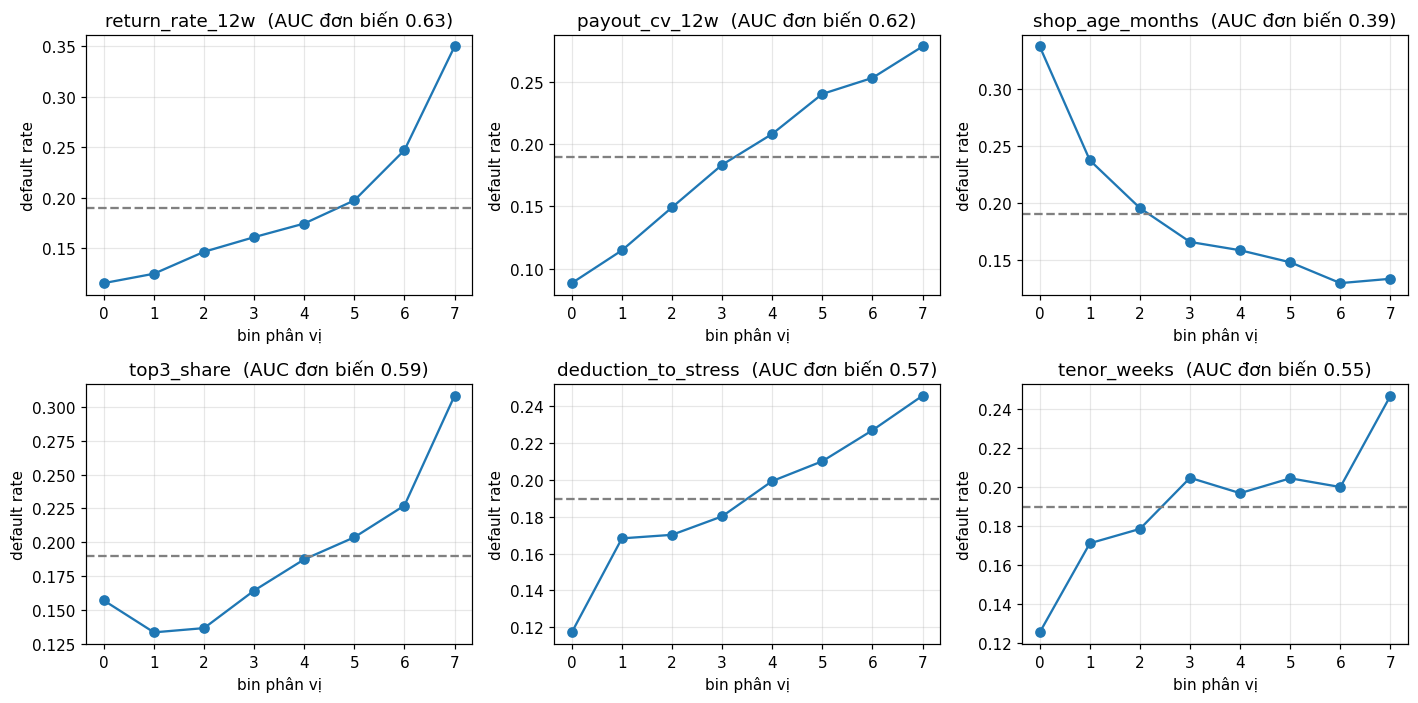

In [4]:
top = uni.index[:6].tolist()
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, c in zip(axes.ravel(), top, strict=True):
    bins = pd.qcut(train[c], 8, duplicates="drop")
    g = train.groupby(bins, observed=True)[LABEL].agg(["mean", "size"])
    ax.plot(range(len(g)), g["mean"], marker="o")
    ax.axhline(train[LABEL].mean(), ls="--", c="grey")
    ax.set_title(f"{c}  (AUC đơn biến {uni.loc[c, 'auc']:.2f})")
    ax.set_xlabel("bin phân vị")
    ax.set_ylabel("default rate")
plt.tight_layout()
plt.show()

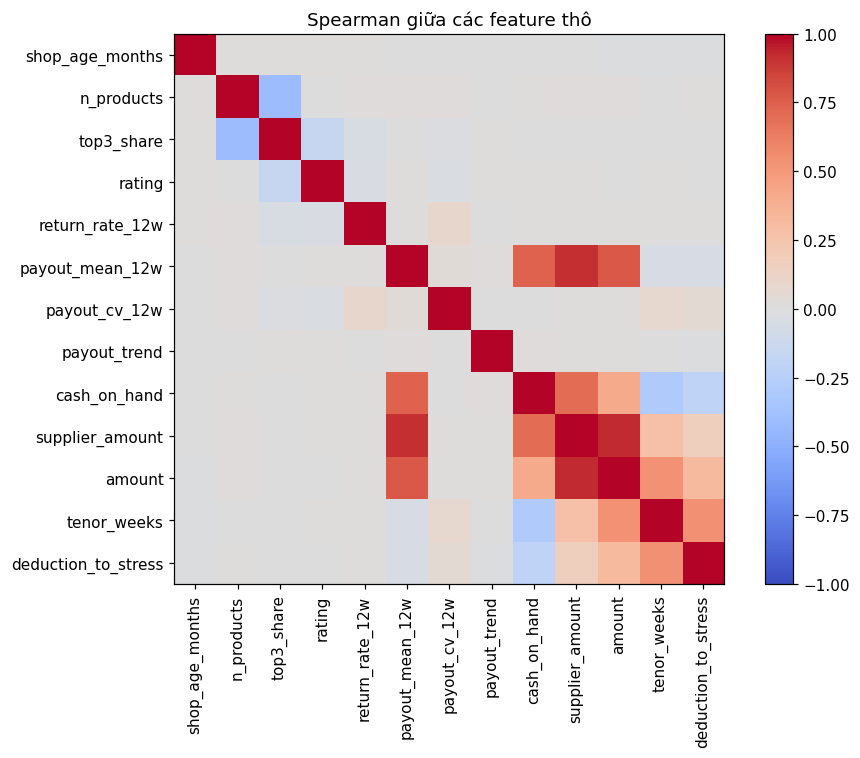

cặp |rho| > 0.8: [('payout_mean_12w', 'supplier_amount', 0.91), ('supplier_amount', 'amount', 0.92)]


In [5]:
corr = train[raw_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(raw_cols)))
ax.set_xticklabels(raw_cols, rotation=90)
ax.set_yticks(range(len(raw_cols)))
ax.set_yticklabels(raw_cols)
ax.set_title("Spearman giữa các feature thô")
ax.grid(False)
plt.colorbar(im)
plt.tight_layout()
plt.show()
high = [
    (a, b, round(float(corr.loc[a, b]), 2))
    for i, a in enumerate(raw_cols)
    for b in raw_cols[i + 1 :]
    if abs(corr.loc[a, b]) > 0.8
]
print("cặp |rho| > 0.8:", high)

Đọc nhanh: `payout_cv_12w`, `return_rate_12w`, `shop_age_months`, `top3_share`, `deduction_to_stress` có tín hiệu đơn biến rõ và đơn điệu, đúng với cơ chế sinh nhãn. `amount`, `cash_on_hand`, `supplier_amount` tương quan cao với nhau vì cùng sinh từ payout, nên trong feature engineering sẽ đưa về tỷ lệ thay vì dùng giá trị tuyệt đối.

## 4. Feature engineering và kiểm tra rò rỉ

`FeatureBuilder` tạo 11 feature gốc, 10 feature dẫn xuất (tỷ lệ khả năng trả nợ, bộ đệm tiền mặt, biến đổi phi tuyến của tuổi shop và mức trích) và one hot archetype. Serving dùng đúng class này nên không lệch train với production.

`shock_weeks` và `short_paid_periods` là kết quả của kỳ trả nợ, biết sau khi cho vay, bị loại. Cell dưới chứng minh nếu để lại thì AUC gần 1, tức là model học nhãn chứ không học rủi ro.

In [6]:
fb = FeatureBuilder()
Xtr, ytr = fb.frame(train), train[LABEL]
Xte, yte = fb.frame(test), test[LABEL].values
print(len(fb.columns), "features:", fb.columns)

leak = ["shock_weeks", "short_paid_periods"]
leaky_model = LgbmTrainer().make(dict(num_leaves=7, max_depth=3, n_estimators=200))
leaky_model.fit(pd.concat([Xtr, train[leak]], axis=1), ytr)
leaky_auc = roc_auc_score(
    yte, leaky_model.predict_proba(pd.concat([Xte, test[leak]], axis=1))[:, 1]
)
print("AUC nếu để lại cột rò rỉ:", round(leaky_auc, 4), "(vô nghĩa)")

25 features: ['shop_age_months', 'n_products', 'top3_share', 'rating', 'return_rate_12w', 'payout_mean_12w', 'payout_cv_12w', 'payout_trend', 'amount', 'tenor_weeks', 'deduction_to_stress', 'age_decay', 'dts_excess', 'log_amount', 'log_payout', 'loan_to_monthly_payout', 'deduction_to_payout', 'cash_weeks_of_deduction', 'cash_cover_ratio', 'tenor_x_cv', 'payout_trend_down', 'arch_fashion', 'arch_electronics', 'arch_fmcg', 'arch_home']


AUC nếu để lại cột rò rỉ: 1.0 (vô nghĩa)


## 5. Trần của dữ liệu

Vì nhãn do mô phỏng sinh ra, ta tính được PD thật của từng hồ sơ test bằng cách chạy lại kỳ trả nợ 200 lần (`data/synth/oracle.py`). AUC của PD thật là trần tuyệt đối: không model nào vượt được vì phần còn lại là ngẫu nhiên thuần túy. Mọi số cao hơn trần này là rò rỉ.

In [7]:
oracle = pd.read_csv(ROOT / "data/synth/test/oracle.csv")
same_shops = (oracle.shop_id.values == test.shop_id.values).all()
same_labels = (oracle.label_default.values == yte).all()
assert same_shops and same_labels, "oracle.csv không cùng seed với test"
oracle_eval = pdlib.evaluate(yte, oracle.oracle_pd.values)
BRIER_FLOOR = pdlib.brier_floor(oracle.oracle_pd.values)
print("oracle:", oracle_eval)
print("sàn Brier (nhiễu không giảm được):", round(BRIER_FLOOR, 4))

oracle: {'auc': 0.8104, 'auc_ci95': [0.7947, 0.8256], 'gini': 0.6208, 'ks': 0.4769, 'pr_auc': 0.532, 'brier': 0.1209, 'ece': 0.0105, 'cal_slope': 0.95, 'cal_intercept': -0.079}
sàn Brier (nhiễu không giảm được): 0.1215


## 6. Baseline: logistic regression (scorecard)

In [8]:
lr = LogisticTrainer()
lr_cv = lr.cv_auc(Xtr, ytr)
lr_model = lr.make().fit(Xtr, ytr)
p_lr = lr_model.predict_proba(Xte)[:, 1]
lr_eval = pdlib.evaluate(yte, p_lr)
print("cv auc", round(lr_cv, 4))
print(lr_eval)
coef = pd.Series(lr_model[-1].coef_[0], index=fb.columns).sort_values()
print(coef.round(3).to_string())

cv auc 0.7556
{'auc': 0.774, 'auc_ci95': [0.7563, 0.7899], 'gini': 0.5481, 'ks': 0.4172, 'pr_auc': 0.4784, 'brier': 0.1283, 'ece': 0.0129, 'cal_slope': 1.074, 'cal_intercept': 0.086}
log_payout                -0.782
tenor_weeks               -0.469
cash_weeks_of_deduction   -0.209
amount                    -0.130
dts_excess                -0.039
arch_electronics          -0.035
deduction_to_stress       -0.017
rating                    -0.008
arch_home                  0.000
arch_fmcg                  0.000
shop_age_months            0.011
payout_trend               0.021
payout_trend_down          0.022
tenor_x_cv                 0.024
arch_fashion               0.035
n_products                 0.042
loan_to_monthly_payout     0.119
cash_cover_ratio           0.150
payout_mean_12w            0.177
deduction_to_payout        0.341
top3_share                 0.424
return_rate_12w            0.465
age_decay                  0.476
payout_cv_12w              0.598
log_amount               

## 7. LightGBM: random search theo OOF AUC, early stopping, learning curve

Tìm kiếm ngẫu nhiên 24 cấu hình trên 5 fold. Chọn theo OOF AUC, không chạm test. Số cây cuối lấy trung bình best iteration của các fold.

In [9]:
gb = LgbmTrainer()
trials = gb.random_search(Xtr, ytr, n_trials=24)
print(trials.head(8).to_string())
params = gb.params_from_row(trials.iloc[0])
oof, iters = gb.oof(params, Xtr, ytr)
N_ROUNDS = int(np.mean(iters))
model = gb.fit_final(params, N_ROUNDS, Xtr, ytr)
p_gb = model.predict_proba(Xte)[:, 1]
gb_eval = pdlib.evaluate(yte, p_gb)
print("chọn:", params, "rounds", N_ROUNDS, "| OOF AUC", round(roc_auc_score(ytr, oof), 4))
print(gb_eval)

   num_leaves  max_depth  min_child_samples  colsample_bytree  reg_lambda   oof_auc  oof_brier  best_iter
0           4          4                200               0.8         0.0  0.756546   0.131210        435
1           4          2                 50               1.0         1.0  0.756495   0.131189        518
2          31          2                200               0.6         1.0  0.756450   0.131192        545
3           7          2                200               0.6        20.0  0.756448   0.131251        602
4           4          4                200               0.8        20.0  0.756368   0.131289        550
5          31          2                100               0.8         1.0  0.756310   0.131172        581
6           4          4                 50               0.8         1.0  0.756289   0.131236        482
7           7          6                 50               0.8         5.0  0.756275   0.131329        326


chọn: {'num_leaves': 4, 'max_depth': 4, 'min_child_samples': 200, 'colsample_bytree': 0.8, 'reg_lambda': 0.0} rounds 435 | OOF AUC 0.7565
{'auc': 0.7723, 'auc_ci95': [0.7557, 0.7891], 'gini': 0.5446, 'ks': 0.4163, 'pr_auc': 0.487, 'brier': 0.1282, 'ece': 0.0217, 'cal_slope': 1.146, 'cal_intercept': 0.177}


 train_rows  logistic_auc  lightgbm_auc  lightgbm_brier
       2000        0.7685        0.7385          0.1352
       5000        0.7737        0.7616          0.1297
      10000        0.7744        0.7672          0.1290
      20000        0.7740        0.7723          0.1282


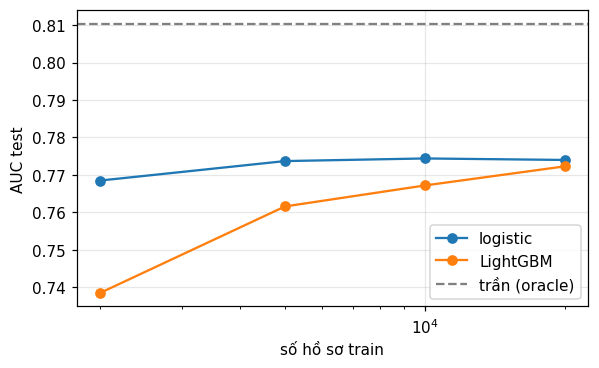

In [10]:
lc = pdlib.learning_curve(
    {"params": params, "n_rounds": N_ROUNDS}, train, test, sizes=(2000, 5000, 10000, 20000)
)
print(lc.to_string(index=False))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(lc.train_rows, lc.logistic_auc, marker="o", label="logistic")
ax.plot(lc.train_rows, lc.lightgbm_auc, marker="o", label="LightGBM")
ax.axhline(oracle_eval["auc"], ls="--", c="grey", label="trần (oracle)")
ax.set_xscale("log")
ax.set_xlabel("số hồ sơ train")
ax.set_ylabel("AUC test")
ax.legend()
plt.show()

## 8. Đánh giá trên test (5.000 hồ sơ, seed khác train)

Mọi số dưới đây là dự đoán trên test sau khi fit trên train. CI 95% bằng bootstrap 300 lần trên test.

                  brier_floor     auc          auc_ci95    gini      ks  pr_auc   brier     ece cal_slope cal_intercept
oracle (PD thật)       0.1215  0.8104  [0.7947, 0.8256]  0.6208  0.4769   0.532  0.1209  0.0105      0.95        -0.079
logistic               0.1215   0.774  [0.7563, 0.7899]  0.5481  0.4172  0.4784  0.1283  0.0129     1.074         0.086
lightgbm               0.1215  0.7723  [0.7557, 0.7891]  0.5446  0.4163   0.487  0.1282  0.0217     1.146         0.177


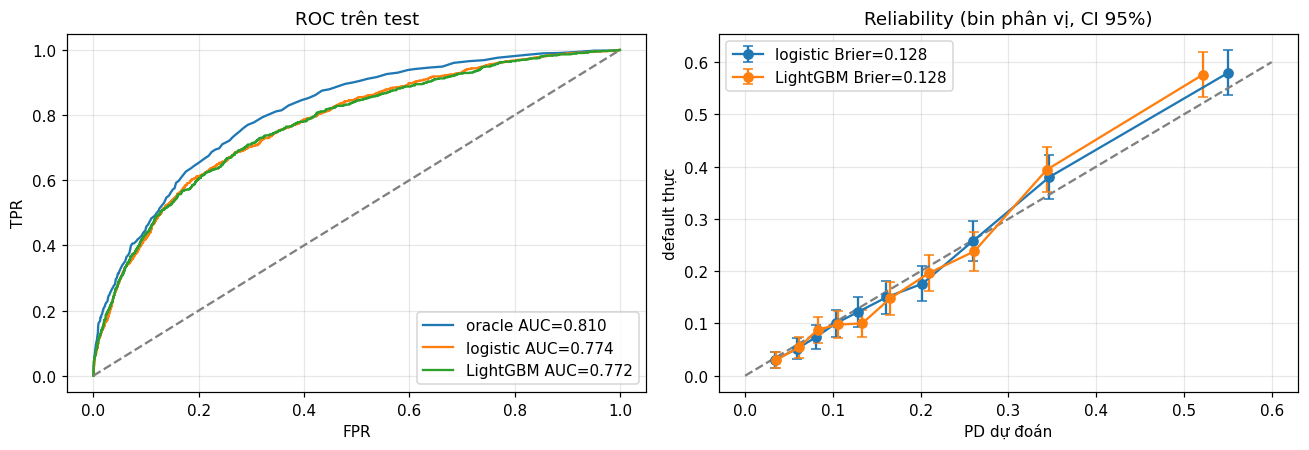

                                  n  pd_mean  actual  actual_lo  actual_hi
bin                                                                       
(0.007859999999999999, 0.0485]  500   0.0355   0.030     0.0150     0.0450
(0.0485, 0.0723]                500   0.0611   0.054     0.0342     0.0738
(0.0723, 0.0937]                500   0.0828   0.088     0.0632     0.1128
(0.0937, 0.119]                 500   0.1060   0.098     0.0719     0.1241
(0.119, 0.147]                  500   0.1333   0.100     0.0737     0.1263
(0.147, 0.185]                  500   0.1654   0.148     0.1169     0.1791
(0.185, 0.233]                  500   0.2090   0.196     0.1612     0.2308
(0.233, 0.295]                  500   0.2612   0.238     0.2007     0.2753
(0.295, 0.405]                  500   0.3436   0.394     0.3512     0.4368
(0.405, 0.906]                  500   0.5216   0.576     0.5327     0.6193


In [11]:
board = pd.DataFrame({"oracle (PD thật)": oracle_eval, "logistic": lr_eval, "lightgbm": gb_eval}).T
board.insert(0, "brier_floor", round(BRIER_FLOOR, 4))
print(board.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for name, p in [("oracle", oracle.oracle_pd.values), ("logistic", p_lr), ("LightGBM", p_gb)]:
    fpr, tpr, _ = roc_curve(yte, p)
    axes[0].plot(fpr, tpr, label=f"{name} AUC={roc_auc_score(yte, p):.3f}")
axes[0].plot([0, 1], [0, 1], "--", c="grey")
axes[0].set(title="ROC trên test", xlabel="FPR", ylabel="TPR")
axes[0].legend()
for name, p in [("logistic", p_lr), ("LightGBM", p_gb)]:
    r = pdlib.reliability_table(yte, p)
    err = 1.96 * np.sqrt(r.actual * (1 - r.actual) / r.n)
    label = f"{name} Brier={brier_score_loss(yte, p):.3f}"
    axes[1].errorbar(r.pd_mean, r.actual, yerr=err, marker="o", capsize=3, label=label)
axes[1].plot([0, 0.6], [0, 0.6], "--", c="grey")
axes[1].set(title="Reliability (bin phân vị, CI 95%)", xlabel="PD dự đoán", ylabel="default thực")
axes[1].legend()
plt.tight_layout()
plt.show()
print(pdlib.reliability_table(yte, p_gb).to_string())

In [12]:
print("AUC theo archetype (LightGBM):")
print(pdlib.segment_auc(yte, p_gb, test["archetype"]).to_string(index=False))
size = pd.cut(
    test["amount"], [0, 30e6, 60e6, 120e6, 300e6], labels=["<30M", "30-60M", "60-120M", ">120M"]
)
print("AUC theo cỡ khoản vay:")
print(pdlib.segment_auc(yte, p_gb, size).to_string(index=False))

AUC theo archetype (LightGBM):
    segment    n  default_rate    auc
electronics 2008        0.1205 0.7331
    fashion 2992        0.2403 0.7670
AUC theo cỡ khoản vay:
segment    n  default_rate    auc
   <30M 1450        0.1724 0.7397
 30-60M 1767        0.1924 0.7972
60-120M 1356        0.2050 0.7813
  >120M  427        0.2178 0.7546


Ổn định qua tập test khác: sinh thêm hai tập test seed 12 và 13, cùng kích thước, để chắc rằng kết quả không phải may mắn của một seed.

In [13]:
rows = []
for s in (11, 12, 13):
    t = test if s == 11 else pdlib.generate_split(5000, s)
    Xs, ys = fb.frame(t), t[LABEL].values
    p_s = model.predict_proba(Xs)[:, 1]
    rows.append(
        {
            "test_seed": s,
            "default_rate": ys.mean().round(4),
            "logistic_auc": roc_auc_score(ys, lr_model.predict_proba(Xs)[:, 1]),
            "lightgbm_auc": roc_auc_score(ys, p_s),
            "lightgbm_brier": brier_score_loss(ys, p_s),
        }
    )
stab = pd.DataFrame(rows).round(4)
print(stab.to_string(index=False))

 test_seed  default_rate  logistic_auc  lightgbm_auc  lightgbm_brier
        11        0.1922        0.7740        0.7723          0.1282
        12        0.1874        0.7842        0.7826          0.1263
        13        0.1972        0.7679        0.7680          0.1327


## 9. Calibration

So ba lựa chọn trên dự đoán out of fold của train, chia đôi: fit trên nửa A, chấm Brier trên nửa B. Chỉ bật calibrator nếu giảm Brier thật. Test không tham gia lựa chọn.

In [14]:
cal = CalibrationSelector().fit(oof, ytr.values)
print(cal.table.to_string())
print("chọn:", cal.method)
p_final = cal.apply(p_gb)
final_eval = pdlib.evaluate(yte, p_final)
print("LightGBM sau calibration:", final_eval)

          brier_holdout  ece_holdout
none             0.1330       0.0062
platt            0.1331       0.0090
isotonic         0.1333       0.0129
chọn: none


LightGBM sau calibration: {'auc': 0.7723, 'auc_ci95': [0.7557, 0.7891], 'gini': 0.5446, 'ks': 0.4163, 'pr_auc': 0.487, 'brier': 0.1282, 'ece': 0.0217, 'cal_slope': 1.146, 'cal_intercept': 0.177}


## 10. Giải thích: SHAP toàn cục, dependence và một hồ sơ cụ thể

SHAP lấy từ `pred_contrib` của LightGBM (TreeSHAP chính xác, không cần thư viện ngoài). Đây cũng là nguồn của `factors` mà API trả về cho memo.

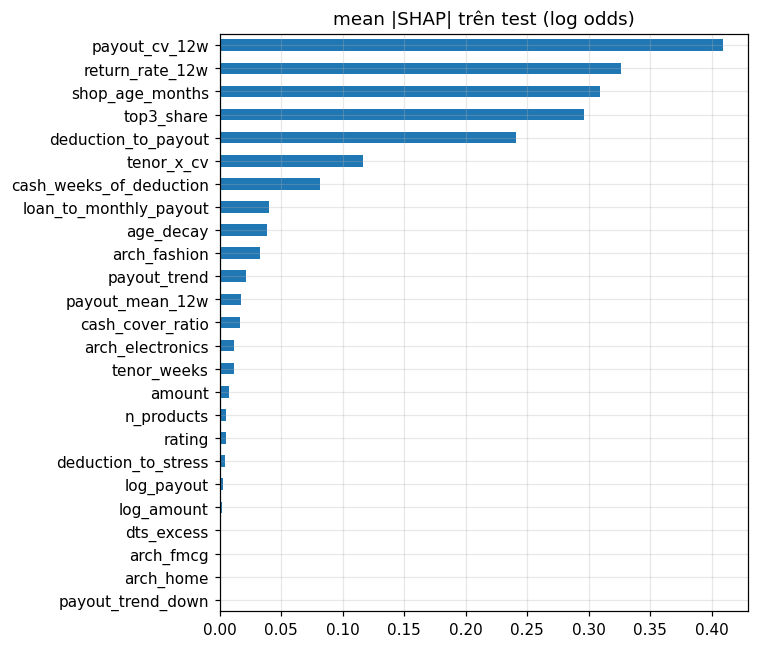

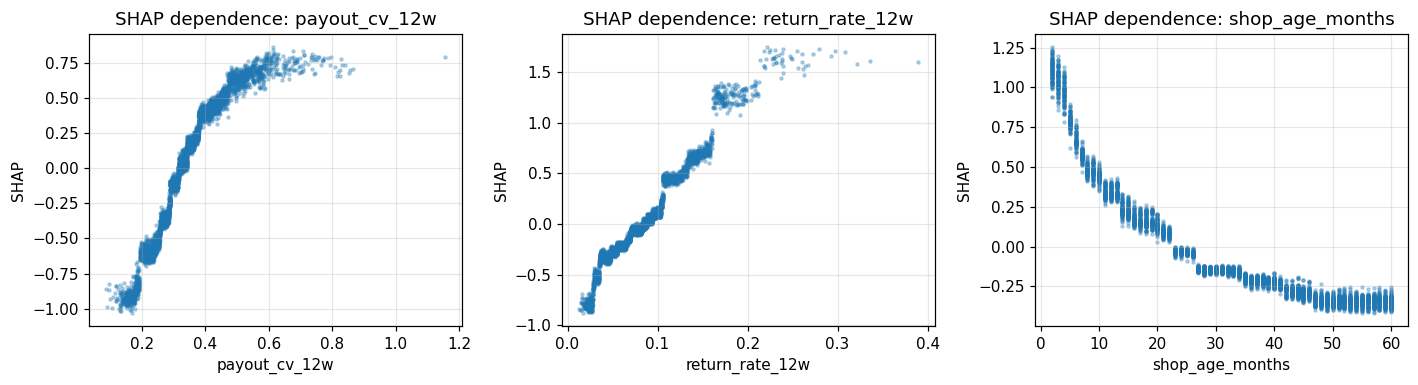

In [15]:
shap = pdlib.shap_values(model, Xte)
imp = shap.abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
imp.plot.barh(ax=ax)
ax.set_title("mean |SHAP| trên test (log odds)")
plt.tight_layout()
plt.show()

top3 = imp.index[-3:][::-1].tolist()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(axes, top3, strict=True):
    ax.scatter(Xte[c], shap[c], s=4, alpha=0.3)
    ax.set(title=f"SHAP dependence: {c}", xlabel=c, ylabel="SHAP")
plt.tight_layout()
plt.show()

In [16]:
CASE_B = dict(
    archetype="fashion",
    shop_age_months=14,
    n_products=80,
    top3_share=0.3,
    rating=4.7,
    return_rate_12w=0.05,
    payout_mean_12w=70_000_000,
    payout_cv_12w=0.2,
    payout_trend=1.0,
    cash_on_hand=120_000_000,
    supplier_amount=200_000_000,
    amount=90_000_000,
    tenor_weeks=8,
    deduction_to_stress=11_250_000 / 49_000_000,
)
xb = pd.DataFrame([fb.row(CASE_B)], columns=fb.columns)
contrib_b = model.booster_.predict(xb, pred_contrib=True)[0][:-1]
sb = pd.Series(contrib_b, index=fb.columns).sort_values(key=abs, ascending=False)
print("Case B PD:", round(float(model.predict_proba(xb)[0, 1]), 4))
print(sb.head(6).round(3).to_string())

Case B PD: 0.0728
payout_cv_12w         -0.596
return_rate_12w       -0.272
tenor_x_cv            -0.230
shop_age_months        0.206
deduction_to_payout    0.143
top3_share            -0.114


## 11. Ngưỡng nghiệp vụ

Model không tự quyết (nguyên tắc 3). Bảng này cho người duyệt và ngân hàng thấy đổi ngưỡng PD thì được gì, mất gì. Lift decile cho thấy 10% hồ sơ rủi ro nhất chứa bao nhiêu phần vỡ nợ.

In [17]:
print(pdlib.cutoff_table(yte, p_final).to_string(index=False))
print(pdlib.decile_table(yte, p_final).to_string())

 pd_cutoff  approval_rate  bad_rate_approved  bad_rate_rejected  defaults_blocked
      0.10         0.3260             0.0620             0.2552            0.8949
      0.15         0.5064             0.0762             0.3112            0.7992
      0.20         0.6320             0.0905             0.3668            0.7024
      0.25         0.7328             0.1084             0.4222            0.5869
      0.30         0.8056             0.1209             0.4877            0.4932
      0.40         0.8972             0.1485             0.5739            0.3070
          n  pd_mean  bad_rate    lift  cum_defaults_share
decile                                                    
1       500   0.0355     0.030  0.1561              1.0000
2       500   0.0611     0.054  0.2810              0.9844
3       500   0.0828     0.088  0.4579              0.9563
4       500   0.1060     0.098  0.5099              0.9105
5       500   0.1333     0.100  0.5203              0.8595
6       500  

## 12. Đóng gói, kiểm tra serving, model card

Artifact ghi vào `api/models/`: booster, calibrator, meta (feature list, hash data, metric, tham số, git sha). `RiskModel.load()` từ chối chạy nếu feature list trong meta không khớp `FeatureBuilder`.

In [18]:
import train_pd  # noqa: E402

from services.risk import RiskModel  # noqa: E402

meta = {
    "model_version": train_pd.MODEL_VERSION,
    "git_sha": train_pd.git_sha(),
    "features": fb.columns,
    "raw_fields": pdlib.RAW_FIELDS,
    "excluded_leak_fields": pdlib.LEAK_FIELDS,
    "params": {**params, "n_estimators": N_ROUNDS},
    "data": {"train": train_info.as_dict(), "test": test_info.as_dict()},
    "metrics": {
        "oracle_test": oracle_eval,
        "brier_floor": round(BRIER_FLOOR, 4),
        "logistic_test": lr_eval,
        "lightgbm_test_raw": gb_eval,
        "lightgbm_test_calibrated": final_eval,
        "lightgbm_oof_auc": round(float(roc_auc_score(ytr, oof)), 4),
        "stability_test_seeds": stab.to_dict("records"),
        "learning_curve": lc.to_dict("records"),
    },
    "calibration": {"method": cal.method, "holdout": cal.table.to_dict()},
    "shap_mean_abs": imp.sort_values(ascending=False).round(4).to_dict(),
    "label": "synthetic, BL-11 (3 kỳ trích thiếu liên tiếp), xem docs/Riverbank-risk-model.md",
}
pdlib.save_artifacts(ROOT / "api" / "models", model, cal, meta)

served = RiskModel.load(ROOT / "api" / "models").predict(CASE_B)
assert abs(served.pd_raw - float(model.predict_proba(xb)[0, 1])) < 1e-4, "serving lệch training"
print("serving Case B:", served.pd, [(f.name, f.direction, f.shap) for f in served.factors[:3]])

serving Case B: 0.0728 [('payout_cv_12w', 'giảm rủi ro', -0.5958), ('return_rate_12w', 'giảm rủi ro', -0.2718), ('tenor_x_cv', 'giảm rủi ro', -0.2304)]


### Model card

| | |
|---|---|
| Mục đích | PD cho khoản vay vốn lưu động seller Shopee, đầu vào của Policy Engine và memo, người duyệt quyết định |
| Dữ liệu | synthetic hiệu chỉnh từ 60 shop thật, nhãn BL-11, train 20.000 seed 7, test 5.000 seed 11 (hash trong meta) |
| Model | LightGBM nông, chọn bằng random search OOF, calibration chỉ bật khi có bằng chứng |
| Kết quả test | xem bảng mục 8 và `api/models/pd_meta.json`, trần dữ liệu ở dòng oracle |
| Giải thích | TreeSHAP, top 5 factor trả qua API |
| Giới hạn | chưa có nhãn vỡ nợ thật, cv từ 12 tuần payout rất nhiễu, không có dữ liệu CIC hay lịch sử tín dụng, PD phải ghi rõ là minh họa trong memo và slide |
| Giám sát khi chạy thật | PSI từng feature so với train mỗi tuần (ngưỡng 0.1 cảnh báo, 0.25 train lại), phân phối PD theo tuần, bad rate thực theo cohort khi có nhãn, calibration slope theo quý |

### Khi có dữ liệu thật

Giữ nguyên pipeline, thay `data/synth/*.csv` bằng bảng hồ sơ thật từ RDS, bỏ phần oracle vì không còn tính được, thay split ngẫu nhiên bằng split theo thời gian (train trước, test sau), và đọc kết quả qua CI bootstrap.

## Kết luận, đọc thật

1. Trên test 5.000 hồ sơ: logistic AUC 0,774 (CI 0,756 đến 0,790), LightGBM 0,772, trần dữ liệu 0,810. Hai model hòa nhau trong CI, cả hai cách trần khoảng 0,04 vì feature quan sát được (cv từ 12 tuần) nhiễu hơn biến ẩn sinh nhãn.
2. Logistic học xong từ 2.000 hồ sơ, LightGBM cần 20.000 mới bắt kịp. Với data gần tuyến tính theo logit thì cây không có lợi thế. Giữ LightGBM làm model phục vụ vì contract `factors` (TreeSHAP) đã có trong API, nhưng phải nói rõ với giám khảo rằng scorecard logistic cho kết quả tương đương và dễ kiểm toán hơn.
3. Brier 0,128 so với sàn 0,122. Calibrator không bật vì trên OOF không giảm Brier. LightGBM hơi thiếu tự tin ở nhóm rủi ro nhất (slope 1,15, bin cuối dự đoán 0,52 thực 0,58), chấp nhận được cho hackathon, với data thật thì fit lại Platt trên tập validation theo thời gian.
4. Ổn định qua 3 seed test: AUC 0,768 đến 0,783, Brier 0,126 đến 0,133.
5. Data chỉ có 2 archetype (electronics, fashion) vì calibration.json lấy từ 41 shop SME thật, nên `arch_fmcg`, `arch_home` hiện bằng 0 toàn bộ. AUC trên electronics thấp hơn (0,73) vì default rate thấp hơn và ít mẫu hơn.
6. Ngưỡng PD 0,20 chặn 70% vỡ nợ với approval rate 63%, bad rate nhóm duyệt 9%. Đây là con số để Policy Engine và người duyệt thảo luận, model không tự chọn ngưỡng.
7. Mọi số trên là trên synthetic. Thứ chuyển được sang data thật là quy trình, contract feature, bộ metric và cách kiểm tra, không phải con số.